# 04 · Protocol P1: random slopes and out-of-sample comparison

This notebook presents the pre-registered protocol P1 from stored artefacts. No model is fitted or scored here: the fits and the final scoring were made by scripts, once each, and stored in `outputs/runs`. Both language versions read the same three P1 runs (`p1_folds`, `gpboost_tuning` and `p1_final`). The P1 metrics are prediction errors of log(units), conditional on the price and promotion realised in the week. Section 9 reads a fourth run for a supplementary inferential test conducted only on the training data after P1 was completed.

*Data: dunnhumby Source Files – Breakfast at the Frat.*

In [1]:
LANG = "en"

In [2]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from retail_multilevel import interpret, viz
from retail_multilevel.i18n import t
from retail_multilevel.runs import load_run

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.4f}".format)
folds = load_run("p1_folds", "20261124-135426-7e46f16b")
tuning = load_run("gpboost_tuning", "20261124-135420-206b7827")
final = load_run("p1_final", "20261124-144615-0aba3b28")
print(t("data_credit", LANG))
stored = {r.metadata["experiment"]: r for r in (folds, tuning, final)}
display(
    pd.DataFrame(
        {name: {"run_id": r.run_id, "finished_at": r.metadata["finished_at"]} for name, r in stored.items()}
    ).T
)

Data: dunnhumby Source Files – Breakfast at the Frat


,run_id,finished_at
p1_folds,20261124-135426-7e46f16b,2026-11-24T13:58:23.622228
gpboost_tuning,20261124-135420-206b7827,2026-11-24T14:39:36.425349
p1_final,20261124-144615-0aba3b28,2026-11-24T14:47:28.624803


The three runs that were read are identified above (identifier and finish time). The identifiers are fixed in the code, so re-running the notebook always reads the same artefacts.

## 1. The question and the pre-registration

The question of the protocol is whether letting the discount elasticity vary across stores and products (random slopes of `LOG_DISC`; Gelman & Hill, 2007) improves out-of-sample prediction, especially for store × product pairs with little history. The reason is that, in a short pair, an elasticity estimated only from the weeks of the pair itself is unstable, and shrinkage (Robinson, 1991) towards the mean of the store and of the product could stabilise it. Notebook 03 estimated a single elasticity common to all pairs, and it is this limitation that P1 examines.

The protocol was pre-registered (Nosek et al., 2018; Weston et al., 2019): it was written and approved, with six amendments (E1 to E6), before any candidate was fitted, and it fixed in advance the candidates, the order of comparison, the stopping rule, the metric and the populations. The amendments defined, among other points, that the initial candidate C0 is the F3 of notebook 03 (E1), how the coverage of the per-pair OLS is measured (E2), the sequential stopping rule (E3) and the freeze that precedes the final evaluation (E6). No threshold or formula was changed after the results of the internal folds were seen.

All candidates share the fixed part of F3 (decisions D12 to D14) and the same rows.

| Candidate | Specification beyond the fixed part of F3 | Status in this notebook |
|---|---|---|
| C0 | Random intercepts for store, product and pair, with a common discount elasticity | Fitted on the folds and on the final window |
| C1 | C0 plus independent random slopes of `LOG_DISC` by product and by store | Fitted on the folds and rejected |
| C2 | C1 with correlated intercept and slope, by product and by store | Not fitted (the sequence stopped) |
| C3 | The better of C1 and C2, plus a random slope of `LOG_DISC` by pair | Not fitted (the sequence stopped) |
| C4 | The best earlier model, plus random slopes of `FEATURE` and `DISPLAY` by product | Not fitted (the sequence stopped) |

Each candidate is compared with the last accepted model, in the order C1, C2, C3, C4. To be accepted, it has to converge without singularity (Bates et al., 2015) and, in case of a warning, with a new attempt using the `nloptwrap` optimiser, have a lower per-pair MAE in both internal folds and reduce the relative MAE by at least 0.5% on average over the folds. If it fails any condition, the last accepted model is kept and the sequence ends, so a later candidate is not fitted when the earlier one fails.

The selection uses two internal folds (Tashman, 2000) within the 104 training weeks. In fold A, the fit uses weeks 0 to 51 and the validation uses weeks 52 to 77. In fold B, the fit uses weeks 0 to 77 and the validation uses weeks 78 to 103. All learned transformations, such as the pair means, are recomputed within each fit window. Only after the selection is the chosen model refitted on weeks 0 to 103 and scored on weeks 104 to 155.

## 2. Metric, populations, references and the freeze

The primary metric is the mean absolute error (MAE) of `LOG_UNITS`, computed first within each pair and then averaged with equal weight per pair. Each pair therefore counts once, regardless of the number of weeks, and the MAE per row (equal weight per row) is reported as a complementary measure. The predictions are conditional on the price and the promotion realised in the week, and the population is the model rows, a retrospective cohort, because the row filter uses information known only after the sale.

Three populations are compared, and the pairs are divided into history strata, counted in the fit window (fewer than 26, 26 to 77, and 78 weeks or more).

| Population | Definition |
|---|---|
| (a) Seen pairs | Pairs present in the fit window. This is the population of the main comparison |
| (b) Rows covered by the per-pair OLS | Subset of (a) in which the per-pair OLS can predict (amendment E2), with all models evaluated on the same rows |
| (c) Unseen pairs | Pairs with no history in the fit window, reported separately, with the pair effect set to zero |

The references are the pooled OLS (the fixed part of F3, without random effects), the per-pair OLS (fitted with `LOG_DISC`, `FEATURE`, `DISPLAY` and `TPR_ONLY`, only in pairs with at least 8 weeks in the fit window) and GPBoost (Sigrist, 2022), a secondary machine-learning challenger with group effects for store, product and pair. The GPBoost hyperparameters were tuned only on the internal folds, and it does not take part in the selection sequence.

**The freeze and the status of the final window.** Before the final evaluation, the selected model (C0), the GPBoost parameters, the code versions and the panel were frozen and recorded in the decision register, and the evaluation of weeks 104 to 155 was planned to be made once, with the result published in either direction. The table below compares the freeze hashes (first 12 characters of the SHA-256) with those computed at scoring time. That window, however, is a **retrospective temporal evaluation window with prior exploratory exposure** (D11, revised): the whole panel was explored before the protocol, and the formulation of the model, such as the price decomposition of D12, is a development decision. It is not an untouched or blind test set.

In [3]:
cfg = final.metadata["config"]
hashes = pd.DataFrame({"frozen": cfg["frozen_hashes"], "at_scoring": cfg["current_hashes"]})
hashes["identical"] = hashes["frozen"] == hashes["at_scoring"]
display(hashes)
display(pd.Series(final.load_json("summary")).to_frame("summary"))

,frozen,at_scoring,identical
p1.py,ea3a8451b6ad,ea3a8451b6ad,True
gpb.py,1f66d53e668a,1f66d53e668a,True
features.py,cc5f2d2e5216,cc5f2d2e5216,True
fixedeffects.py,7b8725e5e6d5,7b8725e5e6d5,True
multilevel.py,bfde1e86abb6,bfde1e86abb6,True
split.py,36ab08e67f0e,36ab08e67f0e,True
cleaning.py,047e1279b041,047e1279b041,True
panel.parquet,f3066b4c7fce,f3066b4c7fce,True


,summary
c0_converged_ok,True
c0_scored,True
n_fit_rows,347092
n_val_rows,177767


## 3. Selection on the internal folds

The table shows the log of the selection sequence. C1 was compared with C0, and the result determined that the sequence stopped.

In [4]:
folds_m = folds.load_table("metrics")
log = interpret.selection_table(folds.load_table("selection_log"), LANG)
display(log.set_index(t("col_candidate", LANG)).T)
display(folds.load_table("convergence"))
display(folds.load_table("coverage").T.rename(columns={0: "A", 1: "B"}))

Candidate,C1,C2,C3,C4
Compared with,C0,C0,C0,C0
"MAE, fold A",0.4294,NaN,NaN,NaN
"MAE, fold A, incumbent",0.4230,NaN,NaN,NaN
"MAE, fold B",0.4188,NaN,NaN,NaN
"MAE, fold B, incumbent",0.4211,NaN,NaN,NaN
"Gain, fold A (%)",-1.5185,NaN,NaN,NaN
"Gain, fold B (%)",0.5432,NaN,NaN,NaN
Mean gain (%),-0.4876,NaN,NaN,NaN
Decision,rejected,not fitted,not fitted,not fitted


,model,fold,n_messages,messages,singular,optimizer,seconds,npar,nobs
0,C0,A,0,,False,bobyqa,18.9982,18,167695
1,C0,B,0,,False,bobyqa,27.5864,18,256650
2,C1,A,0,,False,bobyqa,44.4705,20,167695
3,C1,B,0,,False,bobyqa,84.6404,20,256650


,A,B
fold,A,B
n_seen_pairs,3671,3786
n_seen_rows,87213,90362
n_seen_pairs_with_ols,3635,3757
n_covered_pairs,3631,3756
n_covered_rows,85267,88374
pct_pairs_covered,98.9104,99.2076
pct_rows_covered,97.7687,97.8000
n_unseen_pairs,4,13
n_unseen_rows,32,80


The four fits (C0 and C1 in each fold) converged with the bobyqa optimiser, without messages and without singularity, in 19 to 85 s, with 18 parameters for C0 and 20 for C1. C1 had a per-pair MAE of 0.4294 in fold A, against 0.4230 for C0, a gain of −1.52%, that is, a deterioration. In fold B, the MAE was 0.4188 against 0.4211, a gain of 0.54%. The mean gain, −0.49%, fell below the 0.5% threshold, and the rule rejected C1. C2, C3 and C4 were not fitted.

The coverage of the folds shows that the per-pair OLS covered 98.9% of the pairs and 97.8% of the rows in fold A, and 99.2% and 97.8% in fold B. The unseen pairs are only 4 in fold A (32 rows) and 13 in fold B (80 rows), too few for any conclusion, and in fold A, 1,710 validation rows have no UPC in the fit window and enter only the coverage count.

,Fold,History stratum,Pairs,Rows,C0,C1,Pooled OLS
0,A,All,3671,87213,0.4230,0.4294,0.9149
1,A,< 26 weeks,246,3227,0.3828,0.3686,1.1575
2,A,26-77 weeks,3425,83986,0.4259,0.4338,0.8975
3,B,All,3786,90362,0.4211,0.4188,0.9036
4,B,< 26 weeks,221,3598,0.4999,0.4956,1.0150
5,B,26-77 weeks,1951,44901,0.4676,0.4669,0.9781
6,B,≥ 78 weeks,1614,41863,0.3542,0.3503,0.7983


(b) Rows covered by per-pair OLS


,Fold,History stratum,Pairs,Rows,C0,C1,Per-pair OLS,Pooled OLS
0,A,All,3631,85267,0.4230,0.4305,0.4690,0.9117
1,A,< 26 weeks,208,2735,0.3719,0.3647,0.4346,1.1445
2,A,26-77 weeks,3423,82532,0.4261,0.4345,0.4711,0.8975
3,B,All,3756,88374,0.4190,0.4170,0.4549,0.8987
4,B,< 26 weeks,192,3055,0.4856,0.4904,0.5084,0.9629
5,B,26-77 weeks,1950,44268,0.4671,0.4666,0.5185,0.9768
6,B,≥ 78 weeks,1614,41051,0.3530,0.3483,0.3716,0.7968


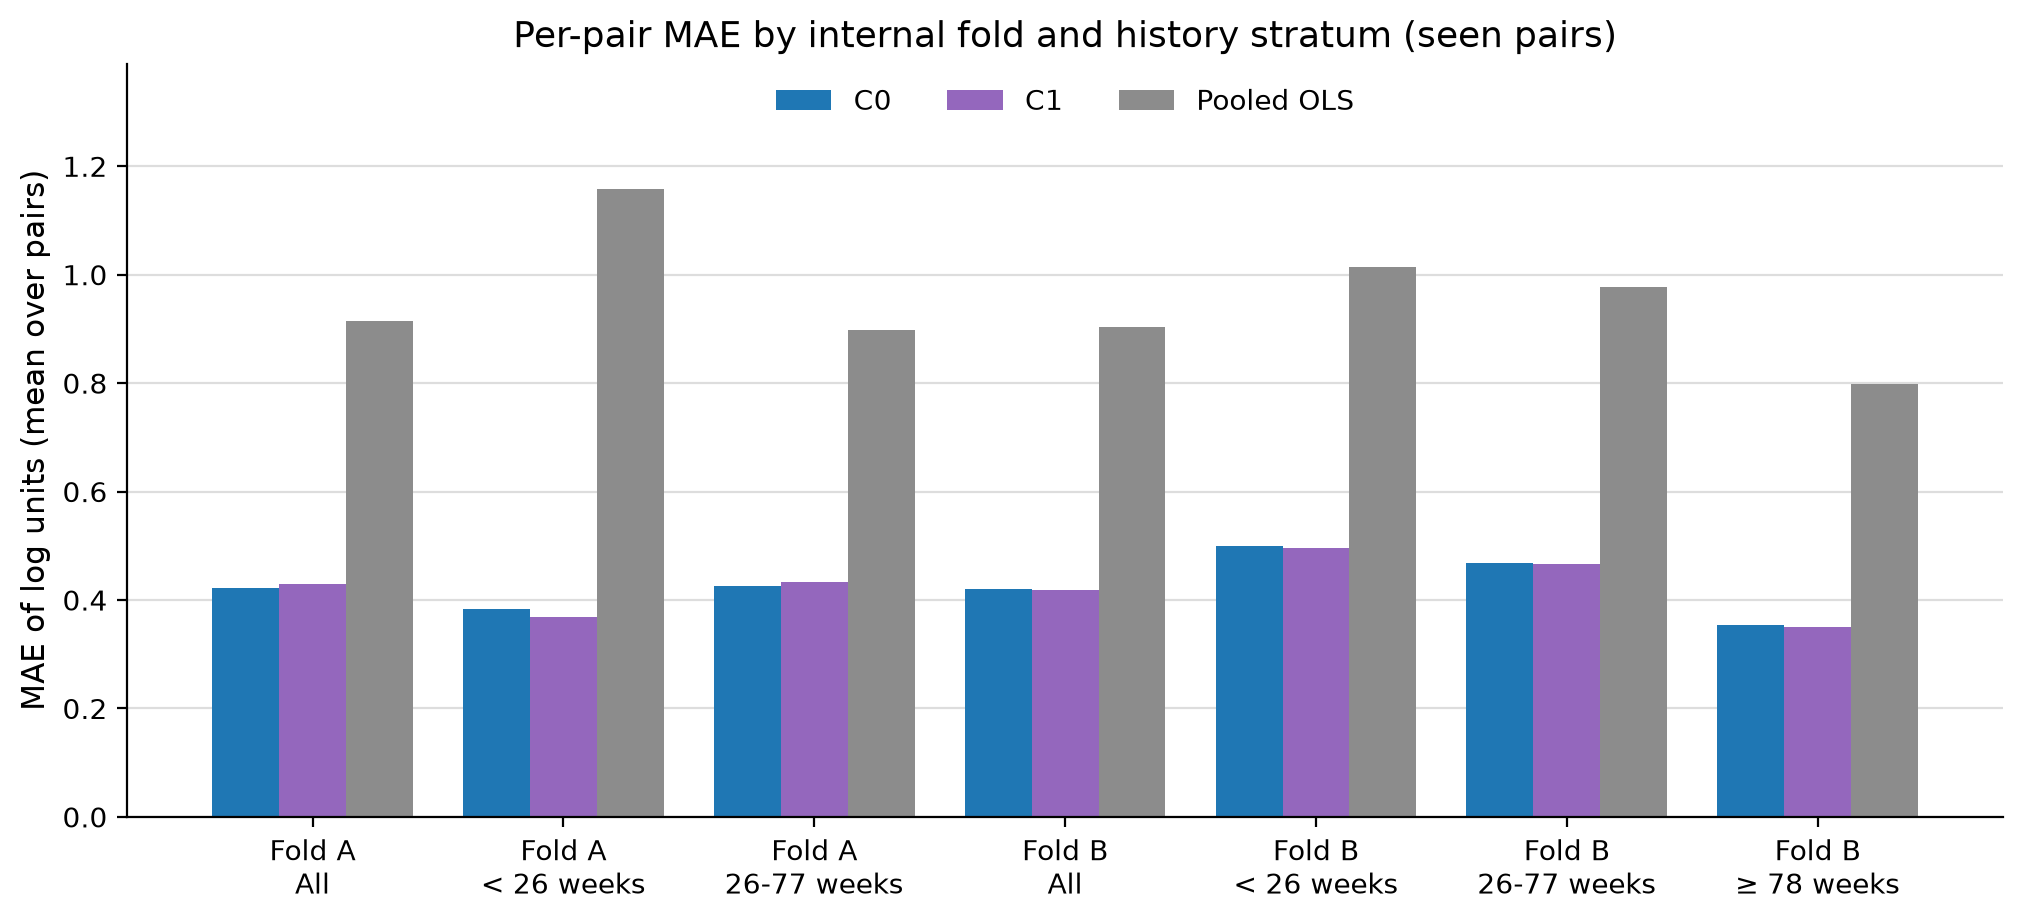

In [5]:
fig = viz.plot_fold_mae(folds_m, LANG)
display(interpret.metric_table(folds_m, "a_seen", LANG, models=["C0", "C1", "OLS_pooled"]))
print(t("pop_b_ols_covered", LANG))
display(interpret.metric_table(folds_m, "b_ols_covered", LANG, models=["C0", "C1", "OLS_pair", "OLS_pooled"]))

The chart and the first table show the per-pair MAE on the seen pairs, by fold and history stratum. The pooled OLS had an MAE of 0.9149 in fold A and 0.9036 in fold B, more than twice that of C0. C1 was better than C0 in the stratum with fewer than 26 weeks in both folds (fold A: 0.3686 against 0.3828; fold B: 0.4956 against 0.4999), in the direction of the hypothesis. It was worse in the 26 to 77 weeks stratum of fold A (0.4338 against 0.4259), which holds 3,425 of the 3,671 pairs of that fold. The stratum of 78 weeks or more is empty in fold A by construction, because the fit window has only 52 weeks. In population (b), C0 had a lower per-pair MAE than the per-pair OLS in both folds (0.4230 against 0.4690 in fold A, and 0.4190 against 0.4549 in fold B).

In [6]:
weekly_folds = folds.load_table("weekly_diff")
display(interpret.weekly_summary_table(weekly_folds, LANG))
display(weekly_folds.loc[weekly_folds.groupby("fold")["mae_diff"].idxmin(), ["fold", "WEEK", "mae_diff"]])

,Fold,Candidate,Reference,Weeks,Weeks candidate is better,Mean difference,Minimum difference,Maximum difference
0,A,C1,C0,26,5,0.0082,-0.0548,0.0278
1,B,C1,C0,26,19,-0.0022,-0.0163,0.0180


,fold,WEEK,mae_diff
9,A,61,-0.0548
35,B,87,-0.0163


The weekly series of the difference between C1 and C0 (negative when C1 is better) reinforces the inconsistency between the folds. In fold A, C1 was better in 5 of the 26 weeks, with a mean difference of +0.0082, that is, worse. In fold B, it was better in 19 of the 26 weeks, with a mean of −0.0022. The largest gain of C1 in fold A, −0.0548, occurred in week 61, the common week shock investigated in notebook 03. A gain that changes sign between the folds is the case in which the rule keeps the simpler model.

## 4. GPBoost tuning

GPBoost was tuned with Optuna (Akiba et al., 2019) and the TPE sampler (Bergstra et al., 2011) over 50 trials, and the objective was the mean, over the two folds, of the per-pair MAE of the seen pairs. To limit the run time, each trial used a fixed subsample of 50% of the pairs of the fit window and at most 300 rounds, without early stopping; both limits are stored in the run's recorded configuration (`fit_frac` and `max_rounds`). The rounds column of the table records the value sampled by the search, before the cap.

In [7]:
best = tuning.load_json("best_params")
trials = tuning.load_table("trials")
space = trials.filter(like="params_").agg(["min", "max"]).T
space.index = space.index.str.removeprefix("params_")
space["selected"] = pd.Series({**best["params"], "num_boost_round": best["num_boost_round"]})
display(space)
print("trials:", len(trials), "| complete:", int((trials["state"] == "COMPLETE").sum()))
print("objective of the selected trial:", round(best["objective"], 4))
display(interpret.gpboost_fold_table(folds_m, tuning.load_table("fold_metrics"), LANG))

,min,max,selected
feature_fraction,0.6007,0.9950,0.6012
lambda_l2,0.0011,5.3865,0.0115
learning_rate,0.0102,0.2116,0.0196
min_data_in_leaf,63.0000,483.0000,459.0000
num_boost_round,55.0000,896.0000,60.0000
num_leaves,8.0000,126.0000,104.0000


trials: 50 | complete: 50
objective of the selected trial: 0.4651


,Fold,"C0, per-pair MAE","GPBoost, per-pair MAE",GPBoost vs. C0 (%)
0,A,0.4230,0.4148,-1.9451
1,B,0.4211,0.4133,-1.8637


The selected parameters were close to the edges of the search space: 60 rounds (the smallest sampled value was 55, and the space starts at 50), `min_data_in_leaf` of 459 (the largest sampled value was 483, and the space ends at 500) and `feature_fraction` of 0.601 (the smallest sampled value was 0.6007, and the space starts at 0.6). The tree part is therefore under-tuned. This is a limitation, and the space was not reopened, because that would be a decision taken after seeing the result.

Refitted on the whole window of each fold, GPBoost had a per-pair MAE of 0.4148 in fold A and 0.4133 in fold B, against 0.4230 and 0.4211 for C0, differences of −1.95% and −1.86%. This comparison favours GPBoost, because its hyperparameters were chosen on those same folds and C0 has no hyperparameters. The fold values are therefore not a fair comparison between the two models.

## 5. The final window (weeks 104 to 155)

C0 was refitted on weeks 0 to 103 (347,092 rows) and scored 177,767 rows of weeks 104 to 155, the retrospective window with prior exploratory exposure. The fit converged with bobyqa, without messages and without singularity, in about 32 s and with 18 parameters. The tables below present the convergence, the coverage of the per-pair OLS and the MAE per pair and per row in each population.

In [8]:
final_m = final.load_table("metrics")
display(final.load_table("convergence"))
display(final.load_table("coverage").T.rename(columns={0: "final"}))
for pop in ("a_seen", "b_ols_covered", "c_unseen"):
    print(t("pop_" + pop, LANG), "|", t("metric_mae_pair", LANG))
    display(interpret.metric_table(final_m, pop, LANG))

,model,fold,n_messages,messages,singular,optimizer,seconds,npar,nobs
0,C0,final,0,,False,bobyqa,32.4328,18,347092


,final
fold,final
n_seen_pairs,3820
n_seen_rows,176529
n_seen_pairs_with_ols,3795
n_covered_pairs,3779
n_covered_rows,174206
pct_pairs_covered,98.9267
pct_rows_covered,98.6841
n_unseen_pairs,50
n_unseen_rows,1238


(a) Seen pairs | MAE per pair


,History stratum,Pairs,Rows,C0,GPBoost,Pooled OLS
0,All,3820,176529,0.4541,0.4520,0.9172
1,< 26 weeks,98,1489,0.5430,0.4376,1.3143
2,26-77 weeks,546,20075,0.4922,0.4791,1.1412
3,≥ 78 weeks,3176,154965,0.4448,0.4478,0.8664


(b) Rows covered by per-pair OLS | MAE per pair


,History stratum,Pairs,Rows,C0,GPBoost,Per-pair OLS,Pooled OLS
0,All,3779,174206,0.4510,0.4506,0.4941,0.9131
1,< 26 weeks,59,1008,0.4773,0.4002,0.4063,1.3420
2,26-77 weeks,544,19040,0.4841,0.4714,0.6127,1.1385
3,≥ 78 weeks,3176,154158,0.4448,0.4479,0.4755,0.8665


(c) Unseen pairs | MAE per pair


,History stratum,Pairs,Rows,C0,GPBoost,Pooled OLS
0,All,50,1238,0.6260,0.6876,0.9925


In [9]:
for pop in ("a_seen", "b_ols_covered", "c_unseen"):
    print(t("pop_" + pop, LANG), "|", t("metric_mae_row", LANG))
    display(interpret.metric_table(final_m, pop, LANG, value="mae_row"))

(a) Seen pairs | MAE per row


,History stratum,Pairs,Rows,C0,GPBoost,Pooled OLS
0,All,3820,176529,0.4446,0.4478,0.8823
1,< 26 weeks,98,1489,0.5232,0.5199,1.1854
2,26-77 weeks,546,20075,0.4900,0.4931,1.0335
3,≥ 78 weeks,3176,154965,0.4380,0.4413,0.8598


(b) Rows covered by per-pair OLS | MAE per row


,History stratum,Pairs,Rows,C0,GPBoost,Per-pair OLS,Pooled OLS
0,All,3779,174206,0.4433,0.4464,0.4771,0.8808
1,< 26 weeks,59,1008,0.4804,0.4888,0.5255,1.1493
2,26-77 weeks,544,19040,0.4845,0.4839,0.5619,1.0351
3,≥ 78 weeks,3176,154158,0.4380,0.4414,0.4664,0.8599


(c) Unseen pairs | MAE per row


,History stratum,Pairs,Rows,C0,GPBoost,Pooled OLS
0,All,50,1238,0.6406,0.6495,0.9194


On the seen pairs (population a), the per-pair MAE was 0.4541 for C0, 0.4520 for GPBoost and 0.9172 for the pooled OLS, and the MAE per row was 0.4446, 0.4478 and 0.8823. By stratum, GPBoost had the lowest per-pair MAE in pairs with fewer than 26 weeks (0.4376 against 0.5430 for C0) and in those with 26 to 77 weeks (0.4791 against 0.4922), and C0 had the lowest in those with 78 weeks or more (0.4448 against 0.4478).

The per-pair OLS had coverage in 3,779 of the 3,820 seen pairs (98.9%) and in 174,206 of the 176,529 rows (98.7%). An estimate was missing for `LOG_DISC` in 23 pairs, for `FEATURE` in 825, for `DISPLAY` in 905 and for `TPR_ONLY` in 382. On those covered rows (population b), the per-pair MAE was 0.4510 for C0, 0.4506 for GPBoost, 0.4941 for the per-pair OLS and 0.9131 for the pooled OLS.

On the 50 unseen pairs (population c, 1,238 rows, none without a covariate), the per-pair MAE was 0.6260 for C0, 0.6876 for GPBoost and 0.9925 for the pooled OLS. The per-pair OLS has no prediction for these pairs.

,Fold,Candidate,Reference,Weeks,Weeks candidate is better,Mean difference,Minimum difference,Maximum difference
0,Final window,C0,Pooled OLS,52,52,-0.4372,-0.4901,-0.3245
1,Final window,C0,Per-pair OLS,52,52,-0.0339,-0.0755,-0.0004
2,Final window,C0,GPBoost,52,30,-0.0032,-0.0659,0.0229


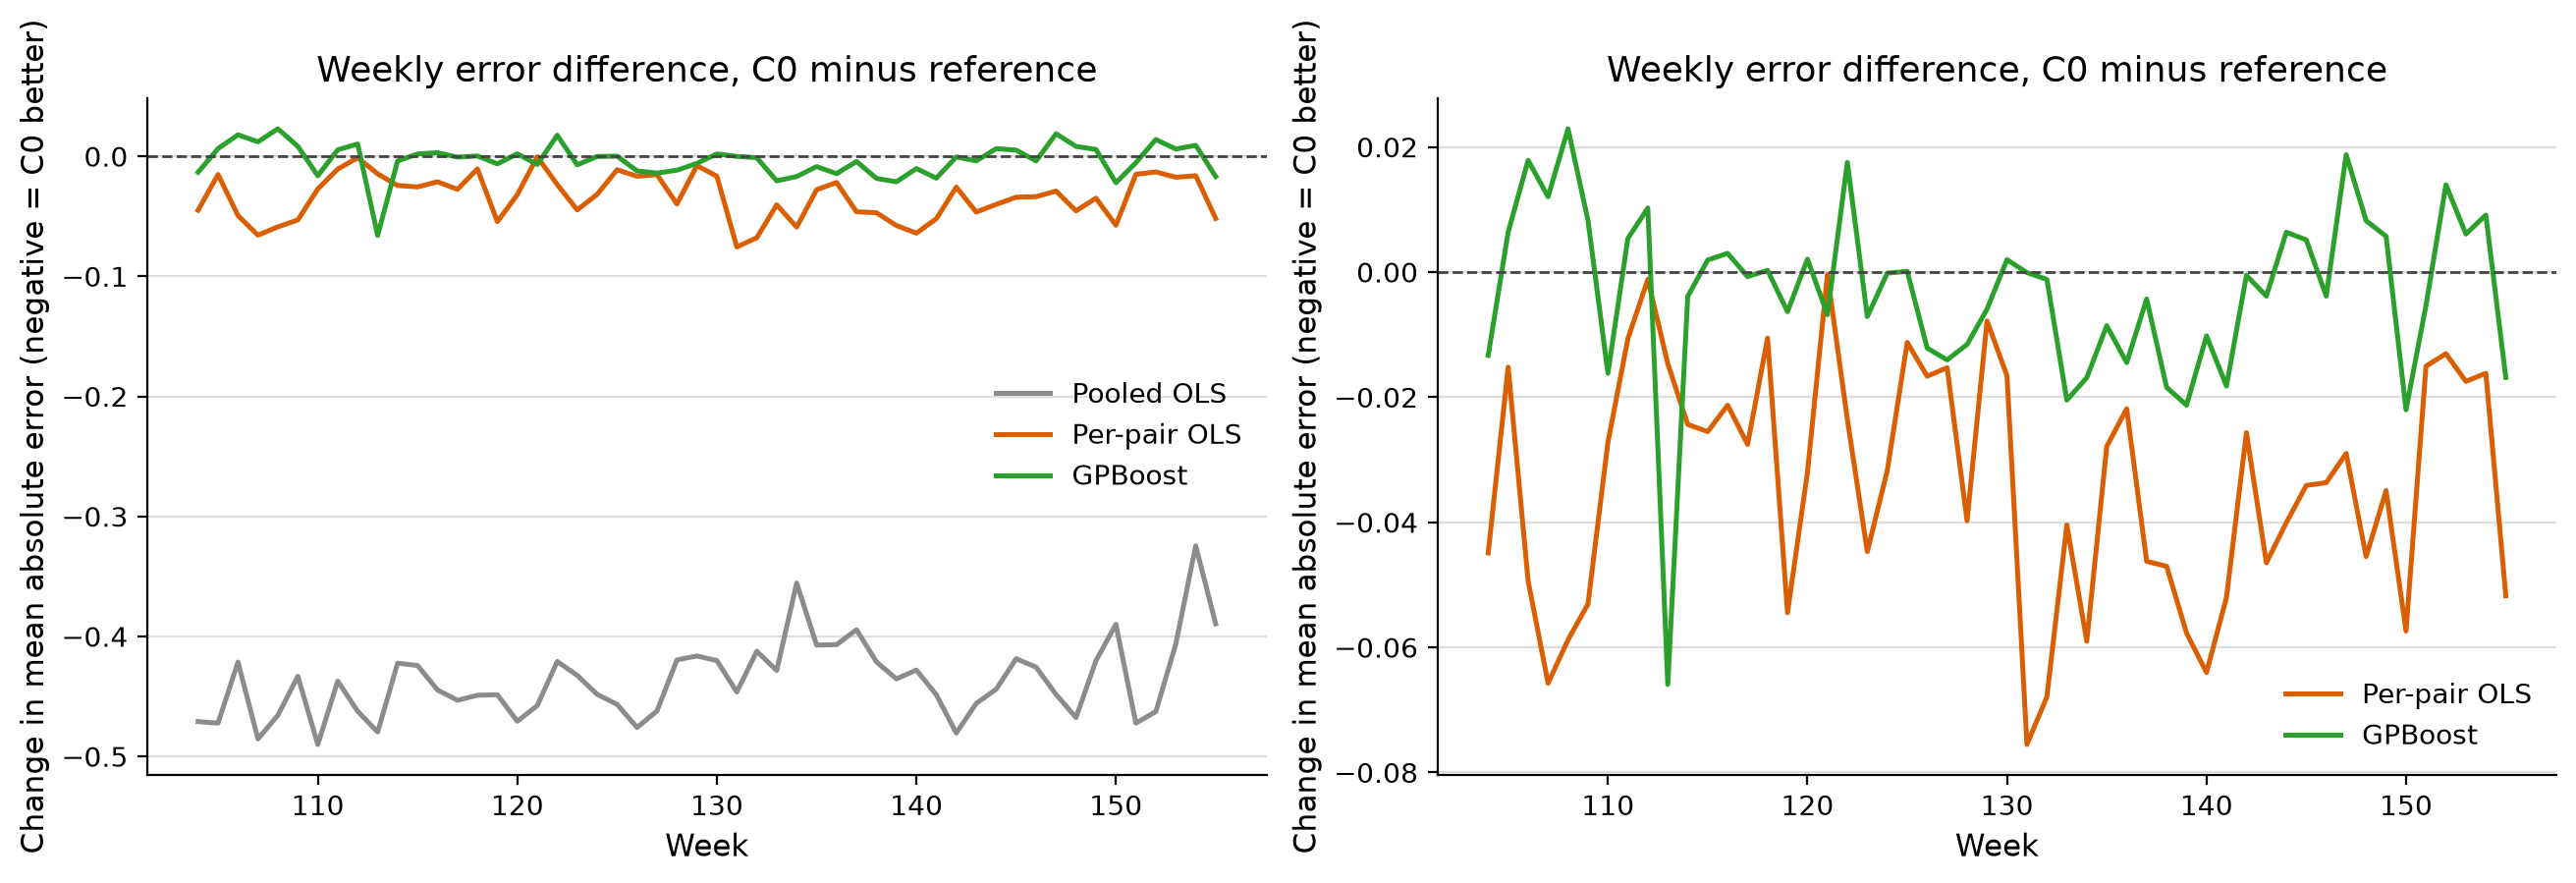

In [10]:
wd = final.load_table("weekly_diff")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
viz.plot_weekly_error_diff(wd, LANG, ax=axes[0])
viz.plot_weekly_error_diff(wd[wd["compared_to"] != "OLS_pooled"], LANG, ax=axes[1])
display(interpret.weekly_summary_table(wd, LANG))

The weekly series shows the error difference between C0 and each reference, defined in the run as the mean, over the rows of the week, of the absolute error of C0 minus that of the reference (negative when C0 is better). It weights rows, not pairs, and is descriptive. C0 was better than the pooled OLS in all 52 weeks (mean difference of −0.4372, from −0.4901 to −0.3245) and better than the per-pair OLS in all 52 weeks (mean of −0.0339, from −0.0755 to −0.0004). Against GPBoost, C0 was better in 30 of the 52 weeks, with a mean of −0.0032, in a range from −0.0659 to +0.0229.

## 6. First conclusion: C0 was selected on fold performance, and random slopes for short pairs remain open

C0 was selected on the performance in the internal folds. C1 improved the short-history stratum (fewer than 26 weeks) in both folds, but failed the global rule: it was worse in fold A, and the mean gain of −0.49% fell below the 0.5% threshold. The table repeats the per-pair MAEs that support the decision.

In [11]:
display(interpret.metric_table(folds_m, "a_seen", LANG, models=["C0", "C1"]))
short = {
    f: interpret.relative_difference(folds_m, "a_seen", "<26", "C1", "C0", fold=f) for f in ("A", "B")
}
label = f"{t('model_c1', LANG)} vs. {t('model_c0', LANG)}, {t('stratum_lt26', LANG)} (%)"
display(pd.Series(short, name=label).to_frame())

,Fold,History stratum,Pairs,Rows,C0,C1
0,A,All,3671,87213,0.4230,0.4294
1,A,< 26 weeks,246,3227,0.3828,0.3686
2,A,26-77 weeks,3425,83986,0.4259,0.4338
3,B,All,3786,90362,0.4211,0.4188
4,B,< 26 weeks,221,3598,0.4999,0.4956
5,B,26-77 weeks,1951,44901,0.4676,0.4669
6,B,≥ 78 weeks,1614,41863,0.3542,0.3503


,"C1 vs. C0, < 26 weeks (%)"
A,-3.7043
B,-0.8524


In the stratum with fewer than 26 weeks, C1 had a per-pair MAE 3.70% lower than that of C0 in fold A and 0.85% lower in fold B. This stratum holds 246 pairs in fold A and 221 in fold B, and the differences are point values, without an uncertainty analysis. In fold A, C1 worsened the 26 to 77 weeks stratum, which holds most of the pairs, and the overall gain was negative.

The final window evaluated C0, which shares information through the intercepts and has a discount slope that is **common** to all pairs. The final window therefore leaves the question of random slopes for short pairs open: C1 was not scored there, by the protocol, and the result of the final window does not say whether the gain of C1 on the short pairs of the folds would hold.

## 7. Second conclusion: C0 and GPBoost performed closely, with results that differ by metric

On the seen pairs, GPBoost had a per-pair MAE 0.47% lower than that of C0 (0.4520 against 0.4541). C0, in turn, had the lowest MAE per row (0.4446 against 0.4478) and the lowest error on the unseen pairs (0.6260 against 0.6876). The table brings these measures together.

In [12]:
specs = [
    ("a_seen", "all", "mae_pair_mean"),
    ("a_seen", "all", "mae_row"),
    ("c_unseen", "all", "mae_pair_mean"),
    ("c_unseen", "all", "mae_row"),
]
display(interpret.model_comparison(final_m, LANG, specs, ["C0", "GPBoost"], rel=("GPBoost", "C0")))
display(interpret.metric_table(final_m, "a_seen", LANG, models=["C0", "GPBoost"]))

,"Population, stratum and metric",C0,GPBoost,Difference (%)
0,(a) Seen pairs · All · MAE per pair,0.4541,0.4520,-0.4654
1,(a) Seen pairs · All · MAE per row,0.4446,0.4478,0.7182
2,(c) Unseen pairs · All · MAE per pair,0.6260,0.6876,9.8364
3,(c) Unseen pairs · All · MAE per row,0.6406,0.6495,1.3745


,History stratum,Pairs,Rows,C0,GPBoost
0,All,3820,176529,0.4541,0.4520
1,< 26 weeks,98,1489,0.5430,0.4376
2,26-77 weeks,546,20075,0.4922,0.4791
3,≥ 78 weeks,3176,154965,0.4448,0.4478


The difference is presented as **observed**. The difference column shows GPBoost 0.47% below C0 in the per-pair MAE of the seen pairs, and 0.72% above in the MAE per row. On the unseen pairs, GPBoost was 9.84% above in the per-pair MAE. The advantage of GPBoost in the per-pair MAE is concentrated in the short and medium history strata, and that of C0 in the stratum of 78 weeks or more. In the weekly series, C0 was better in 30 of the 52 weeks, with a mean difference of −0.0032.

No uncertainty analysis was run for this comparison: the pair bootstrap is deferred, and the weekly series is descriptive. The differences are therefore not declared equivalent or significant. In addition, GPBoost was tuned on the internal folds with a 50% subsample and at most 300 rounds, and with parameters at the edges of the search space (section 4), and its advantage on the folds (about −1.9%) was larger than that observed on the final window (−0.47%).

## 8. Third conclusion: the short-pair result depends on the population and on the weighting

In the 59 short pairs (fewer than 26 weeks) covered by the local OLS, the equal-weight per-pair MAE was 0.4002 for GPBoost, 0.4063 for the local OLS and 0.4773 for C0. In the MAE per row, in that same subset, C0 had a lower error than the local OLS (0.4804 against 0.5255), and GPBoost had 0.4888.

In [13]:
specs = [("b_ols_covered", "<26", "mae_pair_mean"), ("b_ols_covered", "<26", "mae_row")]
display(interpret.model_comparison(final_m, LANG, specs, ["C0", "GPBoost", "OLS_pair"]))
c0 = final_m[(final_m["model"] == "C0") & (final_m["stratum"] == "<26")].set_index("population")
display(
    pd.DataFrame(
        {
            t("pop_a_seen", LANG): c0.loc["a_seen", ["n_pairs", "n_rows"]],
            t("pop_b_ols_covered", LANG): c0.loc["b_ols_covered", ["n_pairs", "n_rows"]],
        }
    ).rename(index={"n_pairs": t("col_pairs", LANG), "n_rows": t("col_rows", LANG)})
)

,"Population, stratum and metric",C0,GPBoost,Per-pair OLS
0,(b) Rows covered by per-pair OLS · < 26 weeks · MAE per pair,0.4773,0.4002,0.4063
1,(b) Rows covered by per-pair OLS · < 26 weeks · MAE per row,0.4804,0.4888,0.5255


,(a) Seen pairs,(b) Rows covered by per-pair OLS
Pairs,98,59
Rows,1489,1008


**Coverage caveat (E2).** Per-pair OLS coverage follows the operational rule applied in the run: a term without variation in the pair's fit window, or dropped by collinearity, counts as not estimated, and a row is uncovered when it has a non-zero value on that term. Only 59 of the 98 short seen pairs are covered, so the subset is selected by the local OLS's own rule and is not a random sample of the short pairs. The operational rule is not equivalent to an estimability criterion. If a promotion was always active in a pair's training window, or always came with the same discount pattern, the intercept or the other terms absorb its average level, but the fit has no basis to estimate what happens when it is switched off or when that relation changes. An estimability criterion, which covers a row only when its covariate vector lies in the space spanned by the pair's training design, would change the classification of 175 of the 176,529 seen-pair rows in the final window, in 63 pairs: 130 currently covered rows would become uncovered and 45 currently uncovered rows would become covered. All changes come from terms dropped by collinearity; the constant-term case changes no row in this window. The stored results were preserved with the operational rule.

The ranking therefore depends on the population and on the weighting. With equal weight per pair, the local OLS (0.4063) was better than C0 (0.4773) in the 59 covered short pairs, and GPBoost (0.4002) was the best of the three. With equal weight per row, in the same subset, C0 (0.4804) was better than the local OLS (0.5255). The two weightings answer different questions, and the stored artefacts do not say which pairs sustain the difference. On the internal folds, in contrast, C0 had a lower per-pair MAE than the per-pair OLS also in the short stratum of the covered rows (section 3 shows population b); the final window did not reproduce that order in the 59 pairs. In that subset, therefore, the idea that the shrinkage of C0 helps mainly the pairs with little history was not confirmed for C0 in the per-pair MAE, and the conclusion does not extend to the short pairs without local OLS coverage.

## 9. Supplementary test of random slopes in training

Notebook 02 used likelihood-ratio tests to compare random-intercept structures. Here, C0 and C1 were compared for the joint hypothesis that the variance of the discount slope across stores and the variance across UPCs are both zero. Both models were fitted by maximum likelihood with the same fixed effects, the same random intercepts and the same 347,092 rows from weeks 0 to 103.

Under the null hypothesis, both variances are on the boundary (Self & Liang, 1987; Stram & Lee, 1994). The test was calibrated by parametric bootstrap under fitted C0, following the procedure of simulating under the restricted model to calibrate the likelihood ratio in mixed models (Halekoh & Højsgaard, 2014; Ott, 2014). In each of the 39 planned replicates, a response was simulated on the same design and both models were refitted to that response. The statistic is twice the difference in log-likelihood between C1 and C0. The Monte Carlo p-value is the number of replicates with a statistic at least as large as the observed one, plus one, divided by the total number of replicates plus one. The results below were read from the stored run without refitting the models.

In [14]:
slope_test = load_run("discount_slope_lr", "20261125-112223-aa33d3e6")
display(interpret.discount_slope_lr_table(slope_test, LANG))

,Measure,Value
0,Observed LR (C0 vs. C1),12974.405
1,Largest simulated LR under C0,5.182
2,Valid / planned replicates,39/39
3,Simulated LR at least as large as observed,0
4,Monte Carlo p-value,0.0250
5,Discount slope SD by store (C1),0.274
6,Discount slope SD by UPC (C1),0.884


The observed LR was **12,974.40**, and the largest simulated LR was **5.18**. None of the 39 valid replicates reached the observed statistic. The Monte Carlo p-value was **0.025**, the finest resolution of the design. Under the model assumptions, the joint test rejects at 5% that both variances are zero. This supports variation in at least one of the two slopes across groups. The separate standard deviation estimates for stores and UPCs describe the C1 fit, and the inferential decision is joint.

The simulation reproduces the residual structure assumed by C0. The residual autocorrelation across weeks within pairs, diagnosed in notebook 03, limits the interpretation of the p-value. The test documents the improvement in fit on training data. For prediction, P1 kept C0 based on error in the temporal folds. Weeks 104 to 155 were outside this supplementary test.

## 10. What remains deferred

Still deferred are the scoring of C1 on the final window, which would be a later exploration and needs approval, and the pair bootstrap for uncertainty in the difference in predictive error between models. The analyses that this notebook left open have since been completed, all on the training weeks and without changing C0 or the ranking recorded here. Notebook 05 ran the secondary contrasts of P1, the interactions of the discount with segment, private label and category, with the Holm correction (Holm, 1979), and the sensitivity with the category × week random effect. Notebook 06 ran the decision layer by scenarios.

In summary, the pre-registered selection kept C0, and the final window, which is retrospective and had prior exploratory exposure, showed C0 better than both OLS references in the aggregate and close to GPBoost, with results that differ by metric and by population. The question about random slopes for short pairs remains open.

## References

Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. In *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (pp. 2623–2631). https://doi.org/10.1145/3292500.3330701

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software, 67*(1), 1–48. https://doi.org/10.18637/jss.v067.i01

Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). Algorithms for hyper-parameter optimization. In *Advances in Neural Information Processing Systems 24*.

Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942

Halekoh, U., & Højsgaard, S. (2014). A Kenward-Roger approximation and parametric bootstrap methods for tests in linear mixed models – The R package pbkrtest. *Journal of Statistical Software, 59*(9), 1–32. https://doi.org/10.18637/jss.v059.i09

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70. (partial verification: source not accessible for automated checking)

Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606. https://doi.org/10.1073/pnas.1708274114

Ott, P. K. (2014). COVTEST: A SAS macro for hypothesis testing in linear mixed effects models via parametric bootstrap. In *SAS Global Forum 2014 Proceedings* (Paper 1558-2014). https://support.sas.com/resources/papers/proceedings14/1558-2014.pdf

Robinson, G. K. (1991). That BLUP is a good thing: The estimation of random effects. *Statistical Science, 6*(1), 15–32. https://doi.org/10.1214/ss/1177011926

Self, S. G., & Liang, K.-Y. (1987). Asymptotic properties of maximum likelihood estimators and likelihood ratio tests under nonstandard conditions. *Journal of the American Statistical Association, 82*(398), 605–610. https://doi.org/10.1080/01621459.1987.10478472

Sigrist, F. (2022). Gaussian process boosting. *Journal of Machine Learning Research, 23*, 1–46.

Stram, D. O., & Lee, J. W. (1994). Variance components testing in the longitudinal mixed effects model. *Biometrics, 50*(4), 1171–1177. https://doi.org/10.2307/2533455

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: An analysis and review. *International Journal of Forecasting, 16*(4), 437–450. https://doi.org/10.1016/S0169-2070(00)00065-0

Weston, S. J., Ritchie, S. J., Rohrer, J. M., & Przybylski, A. K. (2019). Recommendations for increasing the transparency of analysis of preexisting data sets. *Advances in Methods and Practices in Psychological Science, 2*(3), 214–227. https://doi.org/10.1177/2515245919848684